<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session07_support_vector_machines_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۷: ماشین بردار پشتیبان (SVM)

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session07_support_vector_machines.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, SVR
from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
import seaborn as sns

sns.set_theme(style="whitegrid")

def plot_svm(model, X, y, ax, title=""):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=30)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=150, facecolors="none", edgecolors="green", linewidths=2)
    ax.set_title(title)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

در شکل بخش ۱، یکی از نقاطی را که بردار پشتیبان **نیست** حذف کنید و مدل را دوباره آموزش دهید. مرز تغییر می‌کند؟ حالا یک بردار پشتیبان را حذف کنید.

</div>

Removed a non-support vector: w = [-0.013 -0.692], b = -4.154
Removed a support vector: w = [-0.078 -0.667], b = -3.459
Original:                     w = [-0.013 -0.692], b = -4.154


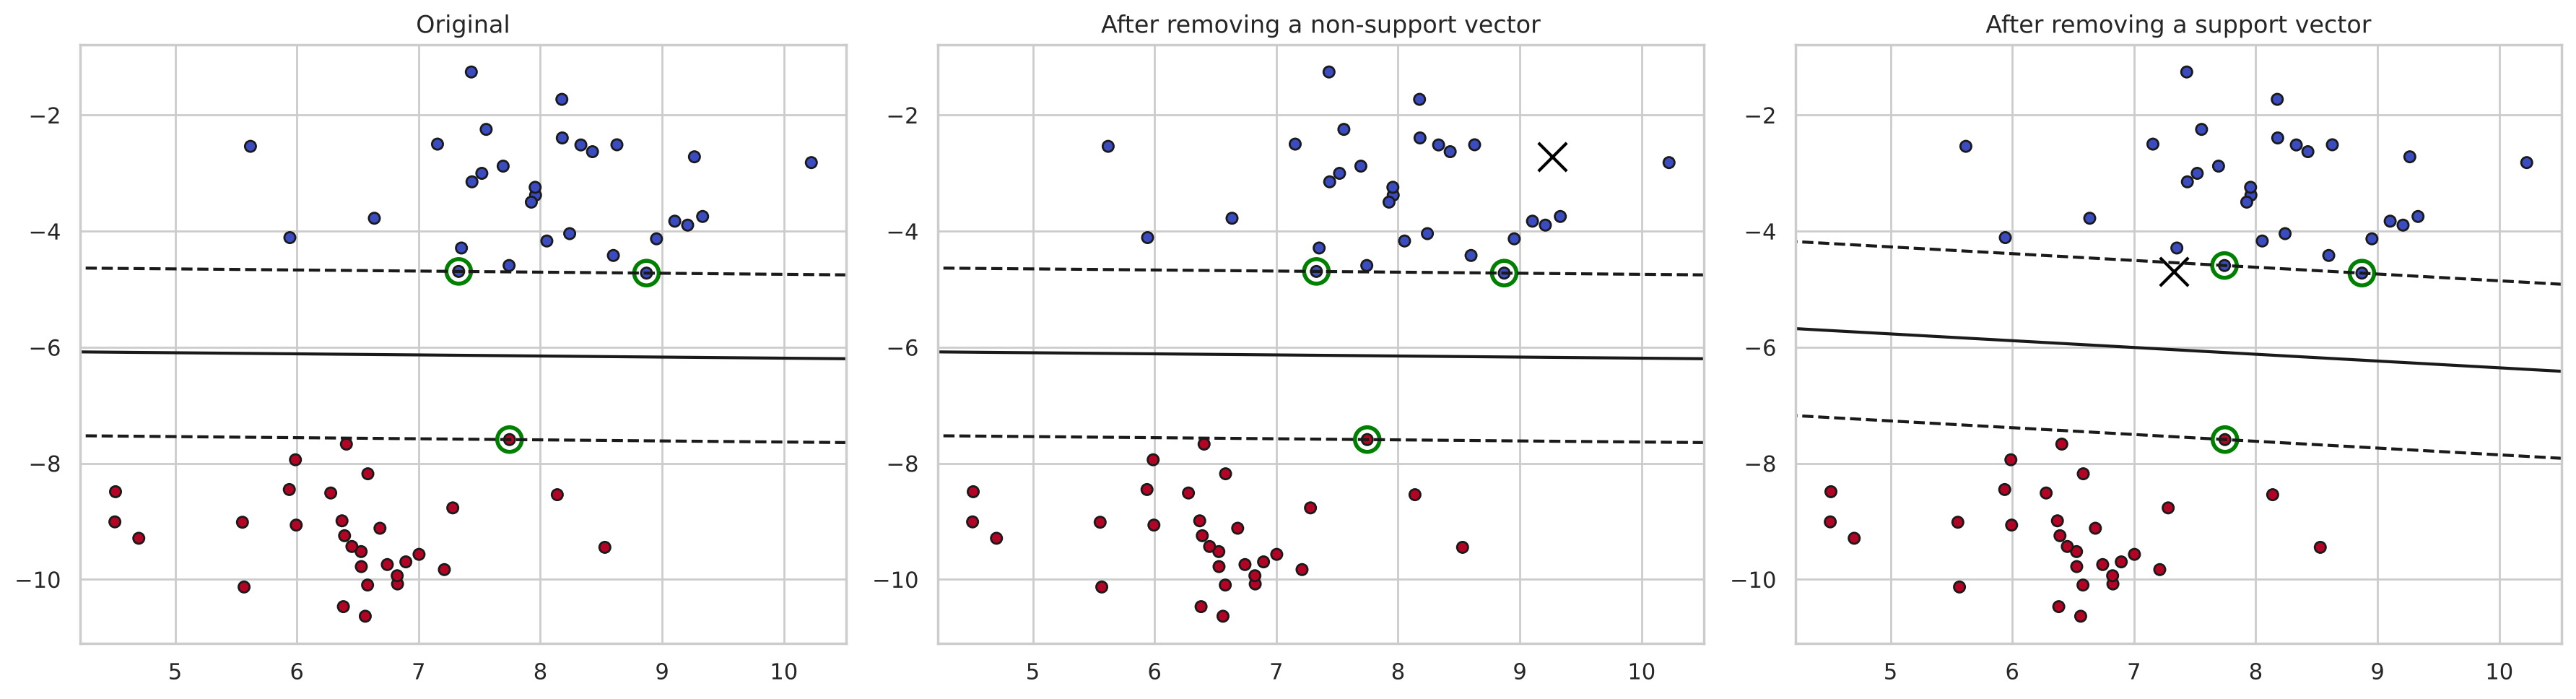

In [2]:
X, y = make_blobs(n_samples=60, centers=2, cluster_std=0.9, random_state=6)
svm = SVC(kernel="linear", C=1000).fit(X, y)
non_sv = np.setdiff1d(np.arange(len(X)), svm.support_)[0]
sv = svm.support_[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_svm(svm, X, y, axes[0], "Original")
for ax, drop, label in [(axes[1], non_sv, "a non-support vector"), (axes[2], sv, "a support vector")]:
    keep = np.arange(len(X)) != drop
    model = SVC(kernel="linear", C=1000).fit(X[keep], y[keep])
    plot_svm(model, X[keep], y[keep], ax, f"After removing {label}")
    ax.scatter(*X[drop], marker="x", s=200, color="black")
    print(f"Removed {label}: w = {model.coef_[0].round(3)}, b = {model.intercept_[0]:.3f}")
print(f"Original:                     w = {svm.coef_[0].round(3)}, b = {svm.intercept_[0]:.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

حذف نقطه‌ای که بردار پشتیبان **نیست**، مرز را ذره‌ای تغییر نمی‌دهد (ضرایب دقیقاً یکسان‌اند). ولی حذف یک بردار پشتیبان، حاشیه و مرز را جابه‌جا می‌کند. این همان ویژگی کلیدی SVM است: مرز فقط به بردارهای پشتیبان بستگی دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

روی دادهٔ moons، `SVC(kernel="poly")` را با درجه‌های ۲، ۳ و ۵ امتحان کنید و مرز تصمیم را رسم کنید.

</div>

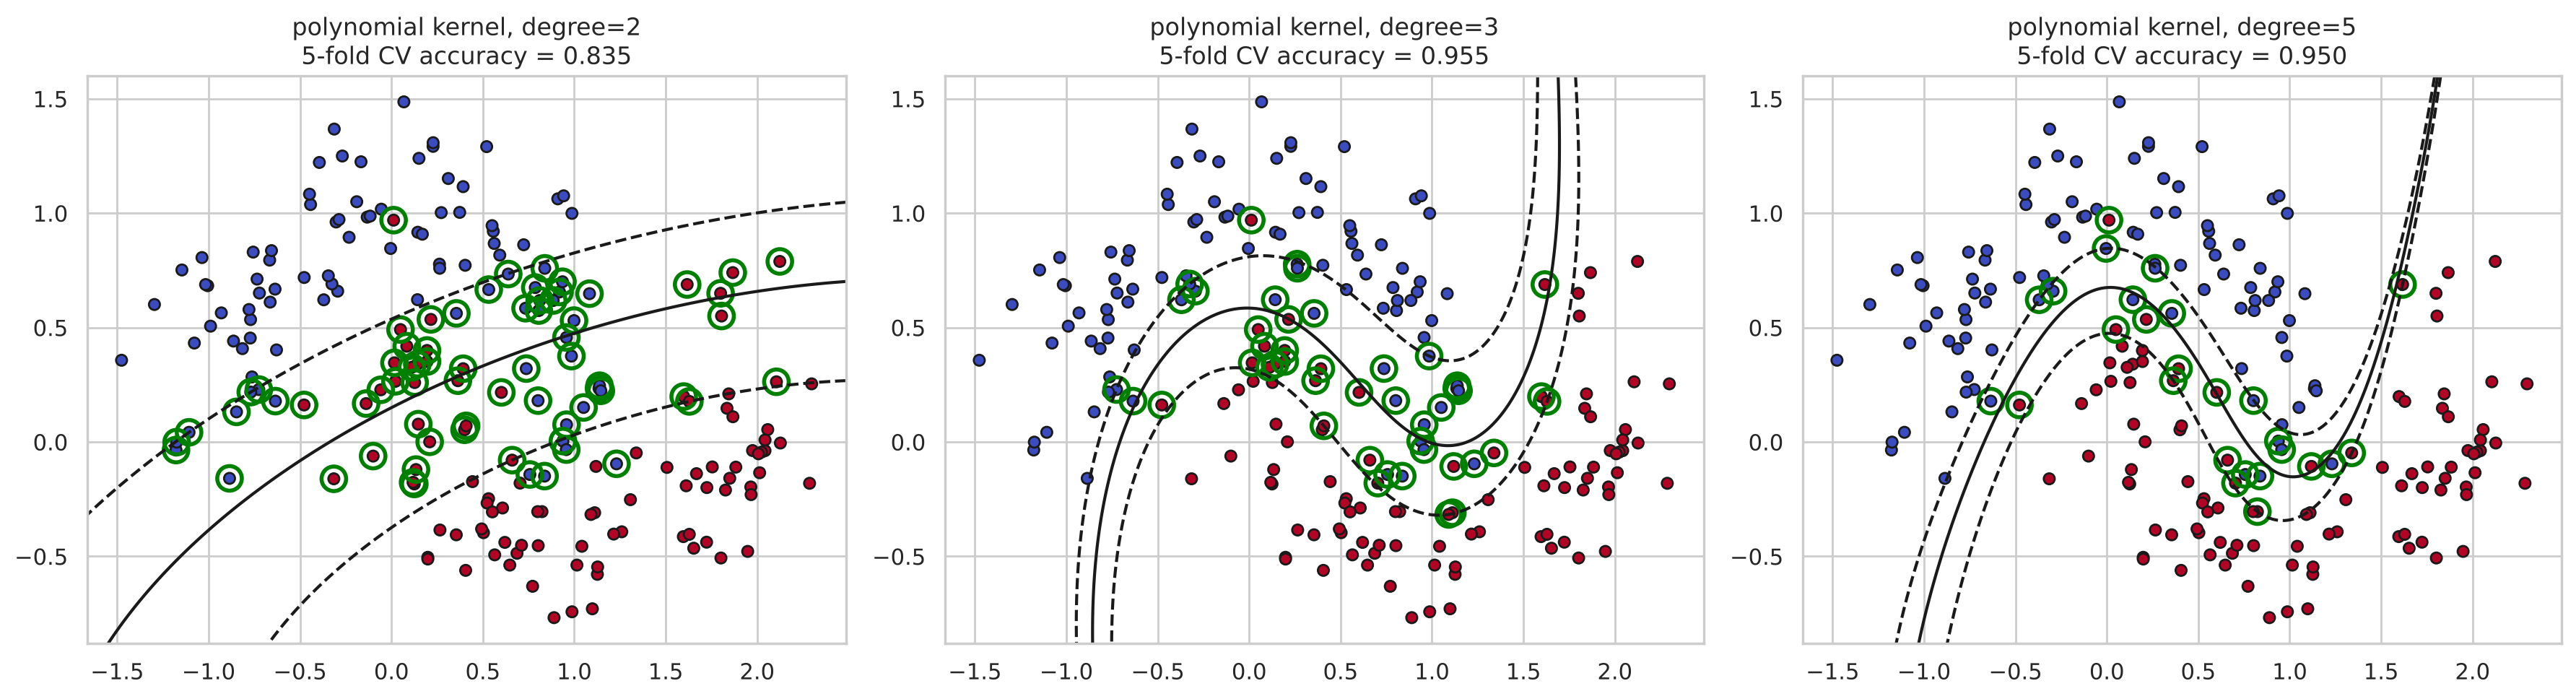

In [3]:
Xm, ym = make_moons(n_samples=200, noise=0.2, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, degree in zip(axes, [2, 3, 5]):
    model = SVC(kernel="poly", degree=degree, coef0=1, C=1).fit(Xm, ym)
    plot_svm(model, Xm, ym, ax, f"polynomial kernel, degree={degree}\n"
                                f"5-fold CV accuracy = {cross_val_score(model, Xm, ym, cv=5).mean():.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

درجهٔ ۲ مرزی به شکل سهمی می‌سازد و نمی‌تواند شکل S مانند دو ماه را کامل بگیرد. درجهٔ ۳ مرز منحنی مناسب‌تری دارد. با درجهٔ ۵ مرز انعطاف بیشتری پیدا می‌کند و خطر بیش‌برازش بالا می‌رود. کرنل چندجمله‌ای با درجهٔ بالا به مقیاس ویژگی‌ها هم بسیار حساس است و از نظر عددی ناپایدار می‌شود؛ به همین دلیل RBF معمولاً انتخاب پیش‌فرض بهتری است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

روی دادهٔ Wine، SVM خطی و RBF را با اعتبارسنجی متقابل مقایسه کنید.

</div>

In [4]:
wine = load_wine()
for kernel in ["linear", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    scores = cross_val_score(model, wine.data, wine.target, cv=5)
    print(f"{kernel:<6} kernel: CV accuracy = {scores.mean():.3f} ± {scores.std():.3f}")

linear kernel: CV accuracy = 0.961 ± 0.014
rbf    kernel: CV accuracy = 0.983 ± 0.022


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو کرنل دقت بسیار بالایی دارند. دادهٔ Wine بعد از استانداردسازی تقریباً **خطی جداپذیر** است (در جلسهٔ ۱۲ با LDA هم دیدیم)، پس کرنل RBF مزیت خاصی ندارد. وقتی داده خطی جداپذیر است، مدل خطی ساده‌تر، سریع‌تر و قابل تفسیرتر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

روی دادهٔ مسکن جلسهٔ ۳، `SVR` را با مقیاس‌بندی امتحان کنید. (راهنمایی: برای سرعت، ابتدا روی ۵۰۰۰ نمونه آموزش دهید.) با رگرسیون خطی مقایسه کنید.

</div>

In [5]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
Xh = housing.drop(columns="median_house_value")
yh = housing["median_house_value"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
Xh_small, yh_small = Xh_train.iloc[:5000], yh_train.iloc[:5000]

numeric = Xh.select_dtypes("number").columns.tolist()
prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
])
models = {
    "Linear regression": LinearRegression(),
    "SVR (default C=1)": SVR(),
    "SVR (C=100000, epsilon=1000)": SVR(C=100_000, epsilon=1000),
}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)]).fit(Xh_small, yh_small)
    print(f"{name:<30} test RMSE = {root_mean_squared_error(yh_test, pipe.predict(Xh_test)):,.0f}")

Linear regression              test RMSE = 69,924


SVR (default C=1)              test RMSE = 116,578


SVR (C=100000, epsilon=1000)   test RMSE = 59,414


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با تنظیمات پیش‌فرض، SVR بسیار بد عمل می‌کند. دلیل: هدف (قیمت) در مقیاس صدها هزار دلار است، ولی `C=1` و `epsilon=0.1` برای هدفی در مقیاس حدود یک طراحی شده‌اند؛ مدل عملاً تقریباً یک عدد ثابت پیش‌بینی می‌کند. با `C` بزرگ متناسب با مقیاس هدف، SVR از رگرسیون خطی بهتر می‌شود. راه بهتر: هدف را هم استاندارد کنید (`TransformedTargetRegressor` با `StandardScaler`) و `C` را با جستجو تنظیم کنید. درس: SVM به مقیاس **هدف** هم، نه فقط ویژگی‌ها، حساس است.

</div>